PEMS-BAY Traffic Speed Forecasting
SimpleRNN vs LSTM vs GRU (Multivariate)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import os
import pickle

In [2]:
df= pd.read_csv(r"L:\4th sem\Mission Scopus\ML Datasets\PEMS-BAY.csv")

In [3]:
df.head()

,Unnamed: 0,400001,400017,400030,400040,400045,400052,400057,400059,400065,...,409525,409526,409528,409529,413026,413845,413877,413878,414284,414694
0,2017-01-01 00:00:00,71.4,67.8,70.5,67.4,68.8,66.6,66.8,68.0,66.8,...,68.8,67.9,68.8,68.0,69.2,68.9,70.4,68.8,71.1,68.0
1,2017-01-01 00:05:00,71.6,67.5,70.6,67.5,68.7,66.6,66.8,67.8,66.5,...,68.4,67.3,68.4,67.6,70.4,68.8,70.1,68.4,70.8,67.4
2,2017-01-01 00:10:00,71.6,67.6,70.2,67.4,68.7,66.1,66.8,67.8,66.2,...,68.4,67.4,68.4,67.5,70.2,68.3,69.8,68.4,70.5,67.9
3,2017-01-01 00:15:00,71.1,67.5,70.3,68.0,68.5,66.7,66.6,67.7,65.9,...,68.5,67.5,68.5,67.5,70.4,68.7,70.2,68.4,70.8,67.6
4,2017-01-01 00:20:00,71.7,67.8,70.2,68.1,68.4,66.9,66.1,67.7,66.1,...,68.5,67.7,68.5,67.4,69.6,69.1,70.0,68.4,71.0,67.9


In [4]:
df.shape

(52116, 326)

In [5]:
df.isnull().sum()

Unnamed: 0    0
400001        0
400017        0
400030        0
400040        0
             ..
413845        0
413877        0
413878        0
414284        0
414694        0
Length: 326, dtype: int64

First column is usually timestamp → drop it

In [6]:
if df.columns[0].lower() in ['timestamp', 'date', 'time', 'datetime'] or '2017' in str(df.iloc[0,0]):
    df = df.drop(df.columns[0], axis=1)

data = df.values.astype(np.float32)
print(f"Raw data shape: {data.shape}")   # Expected: (timesteps, 325)

n_timesteps, n_sensors = data.shape
print(f"Total timesteps : {n_timesteps}")
print(f"Number of sensors: {n_sensors}")

Raw data shape: (52116, 325)
Total timesteps : 52116
Number of sensors: 325


Handle missing values (if any)

In [7]:
print("Missing values:", np.isnan(data).sum())
data = pd.DataFrame(data).ffill().bfill().values   # simple fill

Missing values: 0


Normalize

In [8]:
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

Configuration

In [9]:
N_PAST = 24                         # Past 24 steps = 2 hour
N_FUTURE = 3                        # Predict next 3 steps = 15 minutes
                                    # I can change these freely!

TRAIN_RATIO = 0.6
VAL_RATIO = 0.2
rnn_units = 64

That means in order to predict next 15 minutes, it uses past 2 hours data.

Create sequences

In [10]:
def create_sequences(data, n_past, n_future):
    X, y = [], []
    for i in range(n_past, len(data) - n_future + 1):
        X.append(data[i - n_past : i])
        y.append(data[i : i + n_future])
    return np.array(X), np.array(y)

X, y = create_sequences(data_scaled, N_PAST, N_FUTURE)

print(f"\nX shape: {X.shape}")   # (samples, N_PAST, n_sensors)
print(f"y shape: {y.shape}")   # (samples, N_FUTURE, n_sensors)


X shape: (52090, 24, 325)
y shape: (52090, 3, 325)


Split for Train/Val/Test (time-series aware)

In [11]:
n_samples = len(X)
train_end = int(n_samples * TRAIN_RATIO)
val_end   = int(n_samples * (TRAIN_RATIO + VAL_RATIO))

X_train, y_train = X[:train_end], y[:train_end]
X_val,   y_val   = X[train_end:val_end], y[train_end:val_end]
X_test,  y_test  = X[val_end:], y[val_end:]

print(f"\nTrain: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")


Train: 31254 | Val: 10418 | Test: 10418


In [14]:
y_val

array([[[ 0.17630605, -2.4542606 , -0.38929346, ...,  0.2094382 ,
          0.19096427,  0.31596297],
        [ 0.13935566, -2.5221846 , -0.30351913, ...,  0.0832248 ,
          0.12015024,  0.2568327 ],
        [ 0.18862255, -2.5448263 , -0.41502568, ...,  0.2304735 ,
          0.21929052,  0.29231122]],

       [[ 0.13935566, -2.5221846 , -0.30351913, ...,  0.0832248 ,
          0.12015024,  0.2568327 ],
        [ 0.18862255, -2.5448263 , -0.41502568, ...,  0.2304735 ,
          0.21929052,  0.29231122],
        [ 0.23788942, -2.4391663 , -0.41502568, ...,  0.1673676 ,
          0.2617783 ,  0.3632674 ]],

       [[ 0.18862255, -2.5448263 , -0.41502568, ...,  0.2304735 ,
          0.21929052,  0.29231122],
        [ 0.23788942, -2.4391663 , -0.41502568, ...,  0.1673676 ,
          0.2617783 ,  0.3632674 ],
        [ 0.21325645, -2.310865  , -0.21774481, ...,  0.3566885 ,
          0.19096427,  0.3632674 ]],

       ...,

       [[ 0.5458062 , -1.4127553 , -0.30351913, ...,  0.5249725

Reshape y

In [12]:
y_train_flat = y_train.reshape(len(y_train), -1)
y_val_flat   = y_val.reshape(len(y_val), -1)

In [13]:
y_val_flat

array([[ 0.17630605, -2.4542606 , -0.38929346, ...,  0.2304735 ,
         0.21929052,  0.29231122],
       [ 0.13935566, -2.5221846 , -0.30351913, ...,  0.1673676 ,
         0.2617783 ,  0.3632674 ],
       [ 0.18862255, -2.5448263 , -0.41502568, ...,  0.3566885 ,
         0.19096427,  0.3632674 ],
       ...,
       [ 0.5458062 , -1.4127553 , -0.30351913, ...,  0.65118587,
         0.44589522,  0.15039803],
       [ 0.5458062 , -0.6127581 , -0.14912508, ...,  0.9036143 ,
         0.6158485 ,  0.22135417],
       [ 0.37337264, -0.4316269 ,  0.15966234, ...,  1.050863  ,
         0.7574765 ,  0.3041371 ]], shape=(10418, 975), dtype=float32)

Model Creation and Training for SimpleRNN.

In [15]:
input_layer= Input(shape= (N_PAST, n_sensors), name= "Input_Layer")

In [16]:
rnn= SimpleRNN(units= rnn_units, return_sequences= False, return_state= False, name= "SimpleRNN_Layer")
hidden_layer_first= rnn(input_layer)
hidden_layer_second= Dropout(0.2)(hidden_layer_first)
hidden_layer_third= Dense(128, activation="relu")(hidden_layer_second)
hidden_layer_last= Dropout(0.2)(hidden_layer_third)
output_layer= Dense(units= N_FUTURE*n_sensors, activation= "linear", name= "Output_Layer")(hidden_layer_last)

In [17]:
model= Model(inputs= input_layer, outputs= output_layer)

In [18]:
model.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

This time I will use Early Stopping and Reduce LR On Plateau, in order to reduce overfitting.

In [19]:
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1)
reduce_lr  = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)

In [20]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 24, 325)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 975)            │       125,775 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 159,055 (621.31 KB)

 Trainable params: 159,055 (621.31 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
simple_rnn_model= model.fit(X_train, y_train_flat, validation_data=(X_val, y_val_flat), epochs= 10, batch_size= 128, callbacks=[early_stop, reduce_lr], verbose= 1)

Epoch 1/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - loss: 0.3889 - mae: 0.3624 - val_loss: 0.3769 - val_mae: 0.3257 - learning_rate: 0.0010
Epoch 2/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - loss: 0.2832 - mae: 0.3025 - val_loss: 0.3538 - val_mae: 0.3109 - learning_rate: 0.0010
Epoch 3/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - loss: 0.2650 - mae: 0.2932 - val_loss: 0.3386 - val_mae: 0.3040 - learning_rate: 0.0010
Epoch 4/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - loss: 0.2534 - mae: 0.2879 - val_loss: 0.3317 - val_mae: 0.3034 - learning_rate: 0.0010
Epoch 5/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - loss: 0.2458 - mae: 0.2844 - val_loss: 0.3258 - val_mae: 0.3004 - learning_rate: 0.0010
Epoch 6/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - loss: 0.2414 - mae: 0.2823 - val_loss: 0.3196 - val_mae: 0.2975 - learning_rate: 0.0010
Epoch 7/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - loss: 0.2380 - mae: 0.2802 - val_loss: 0.3154 - val_mae: 0.2949 - learning_rate: 0.00

Model Creation and Training for LSTM.

In [22]:
rnn2= LSTM(units= rnn_units, return_sequences= False, return_state= False, name= "LSTM_Layer")
hidden_layer_first2= rnn(input_layer)
hidden_layer_second2= Dropout(0.2)(hidden_layer_first2)
hidden_layer_third2= Dense(128, activation="relu")(hidden_layer_second2)
hidden_layer_last2= Dropout(0.2)(hidden_layer_third2)
output_layer2= Dense(units= N_FUTURE*n_sensors, activation= "linear", name= "Output_Layer")(hidden_layer_last2)

In [23]:
model2= Model(inputs= input_layer, outputs= output_layer2)

In [24]:
model2.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

In [25]:
model2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 24, 325)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 975)            │       125,775 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 159,055 (621.31 KB)

 Trainable params: 159,055 (621.31 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
lstm_model= model2.fit(X_train, y_train_flat, validation_data=(X_val, y_val_flat), epochs= 10, batch_size= 128, callbacks=[early_stop, reduce_lr], verbose= 1)

Epoch 1/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 16s 54ms/step - loss: 0.3777 - mae: 0.3575 - val_loss: 0.3599 - val_mae: 0.3152 - learning_rate: 0.0010
Epoch 2/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 16s 46ms/step - loss: 0.2690 - mae: 0.2988 - val_loss: 0.3390 - val_mae: 0.3069 - learning_rate: 0.0010
Epoch 3/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 12s 47ms/step - loss: 0.2521 - mae: 0.2904 - val_loss: 0.3316 - val_mae: 0.3058 - learning_rate: 0.0010
Epoch 4/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - loss: 0.2440 - mae: 0.2860 - val_loss: 0.3211 - val_mae: 0.2990 - learning_rate: 0.0010
Epoch 5/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 12s 49ms/step - loss: 0.2384 - mae: 0.2830 - val_loss: 0.3149 - val_mae: 0.2976 - learning_rate: 0.0010
Epoch 6/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - loss: 0.2345 - mae: 0.2807 - val_loss: 0.3125 - val_mae: 0.2963 - learning_rate: 0.0010
Epoch 7/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - loss: 0.2313 - mae: 0.2789 - val_loss: 0.3121 - val_mae: 0.2973 - learning_rate:

Model Creation and Training for GRU.

In [27]:
rnn3= GRU(units= rnn_units, return_sequences= False, return_state= False, name= "GRU_Layer")
hidden_layer_first3= rnn(input_layer)
hidden_layer_second3= Dropout(0.2)(hidden_layer_first3)
hidden_layer_third3= Dense(128, activation="relu")(hidden_layer_second3)
hidden_layer_last3= Dropout(0.2)(hidden_layer_third3)
output_layer3= Dense(units= N_FUTURE*n_sensors, activation= "linear", name= "Output_Layer3")(hidden_layer_last3)

In [28]:
model3= Model(inputs= input_layer, outputs= output_layer3)

In [29]:
model3.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

In [30]:
model3.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 24, 325)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer3 (Dense)           │ (None, 975)            │       125,775 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 159,055 (621.31 KB)

 Trainable params: 159,055 (621.31 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
gru_model= model3.fit(X_train, y_train_flat, validation_data=(X_val, y_val_flat), epochs= 10, batch_size= 128, callbacks=[early_stop, reduce_lr], verbose= 1)

Epoch 1/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - loss: 0.3755 - mae: 0.3577 - val_loss: 0.3577 - val_mae: 0.3166 - learning_rate: 0.0010
Epoch 2/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - loss: 0.2686 - mae: 0.2992 - val_loss: 0.3322 - val_mae: 0.3029 - learning_rate: 0.0010
Epoch 3/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - loss: 0.2506 - mae: 0.2900 - val_loss: 0.3244 - val_mae: 0.3026 - learning_rate: 0.0010
Epoch 4/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - loss: 0.2417 - mae: 0.2855 - val_loss: 0.3192 - val_mae: 0.3006 - learning_rate: 0.0010
Epoch 5/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 0.2364 - mae: 0.2828 - val_loss: 0.3171 - val_mae: 0.2994 - learning_rate: 0.0010
Epoch 6/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - loss: 0.2338 - mae: 0.2812 - val_loss: 0.3102 - val_mae: 0.2958 - learning_rate: 0.0010
Epoch 7/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - loss: 0.2306 - mae: 0.2791 - val_loss: 0.3103 - val_mae: 0.2962 - learning_rate: 0.0

Binding 3 models

In [32]:
models = {
    "SimpleRNN": model,
    "LSTM": model2,
    "GRU": model3,
}

results = {}

In [33]:
history = {"SimpleRNN": model.history.history, "LSTM": model2.history.history, "GRU": model3.history.history}

Evaluate

In [34]:
for name, m in models.items():
    loss, mae = m.evaluate(X_test, y_test.reshape(len(y_test), -1), verbose=0)
    results[name] = {"mse": loss, "mae": mae}
    print(f"{name} → Test MAE: {mae:.4f}")

SimpleRNN → Test MAE: 0.4049
LSTM → Test MAE: 0.3411
GRU → Test MAE: 0.3105


Detailed Metrics (original scale)

In [36]:
def calc_metrics(y_true, y_pred):
    y_true = y_true.reshape(-1, N_FUTURE, n_sensors)
    y_pred = y_pred.reshape(-1, N_FUTURE, n_sensors)
    
    # Inverse transform
    y_true_inv = np.zeros_like(y_true)
    y_pred_inv = np.zeros_like(y_pred)
    
    for t in range(N_FUTURE):
        y_true_inv[:, t, :] = scaler.inverse_transform(y_true[:, t, :])
        y_pred_inv[:, t, :] = scaler.inverse_transform(y_pred[:, t, :])
    
    mae  = mean_absolute_error(y_true_inv.flatten(), y_pred_inv.flatten())
    rmse = np.sqrt(mean_squared_error(y_true_inv.flatten(), y_pred_inv.flatten()))
    
    return mae, rmse, y_true_inv, y_pred_inv

print("\n" + "="*60)
print("FINAL RESULTS (Original Scale - mph)")
print("="*60)

final_results = {}
for name, model in models.items():
    y_pred = model.predict(X_test, verbose=0)
    mae, rmse, _, _ = calc_metrics(y_test, y_pred)
    final_results[name] = {"MAE": mae, "RMSE": rmse}
    print(f"{name:12} → MAE: {mae:.3f} mph | RMSE: {rmse:.3f} mph")

results_df = pd.DataFrame(final_results).T.sort_values("MAE")
print("\nBest model:", results_df.index[0])


FINAL RESULTS (Original Scale - mph)
SimpleRNN    → MAE: 3.328 mph | RMSE: 6.092 mph
LSTM         → MAE: 2.735 mph | RMSE: 4.952 mph
GRU          → MAE: 2.435 mph | RMSE: 4.506 mph

Best model: GRU


Plot Training History

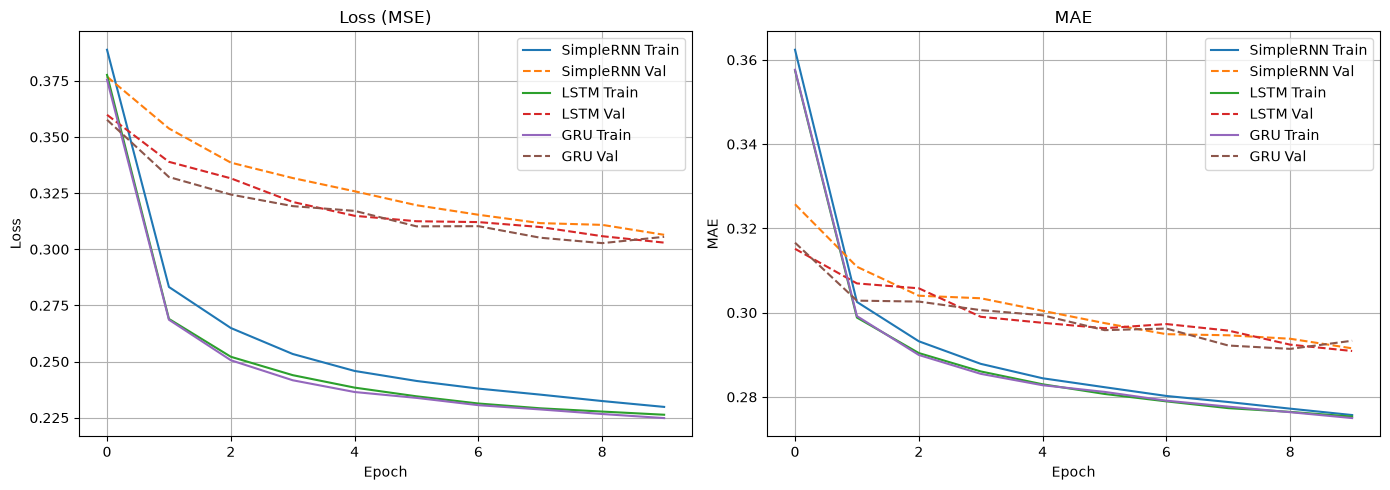

In [37]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for name, hist in history.items():
    plt.plot(hist['loss'], label=f'{name} Train')
    plt.plot(hist['val_loss'], label=f'{name} Val', linestyle='--')
plt.title('Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for name, hist in history.items():
    plt.plot(hist['mae'], label=f'{name} Train')
    plt.plot(hist['val_mae'], label=f'{name} Val', linestyle='--')
plt.title('MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Visualize Predictions (Best Model)

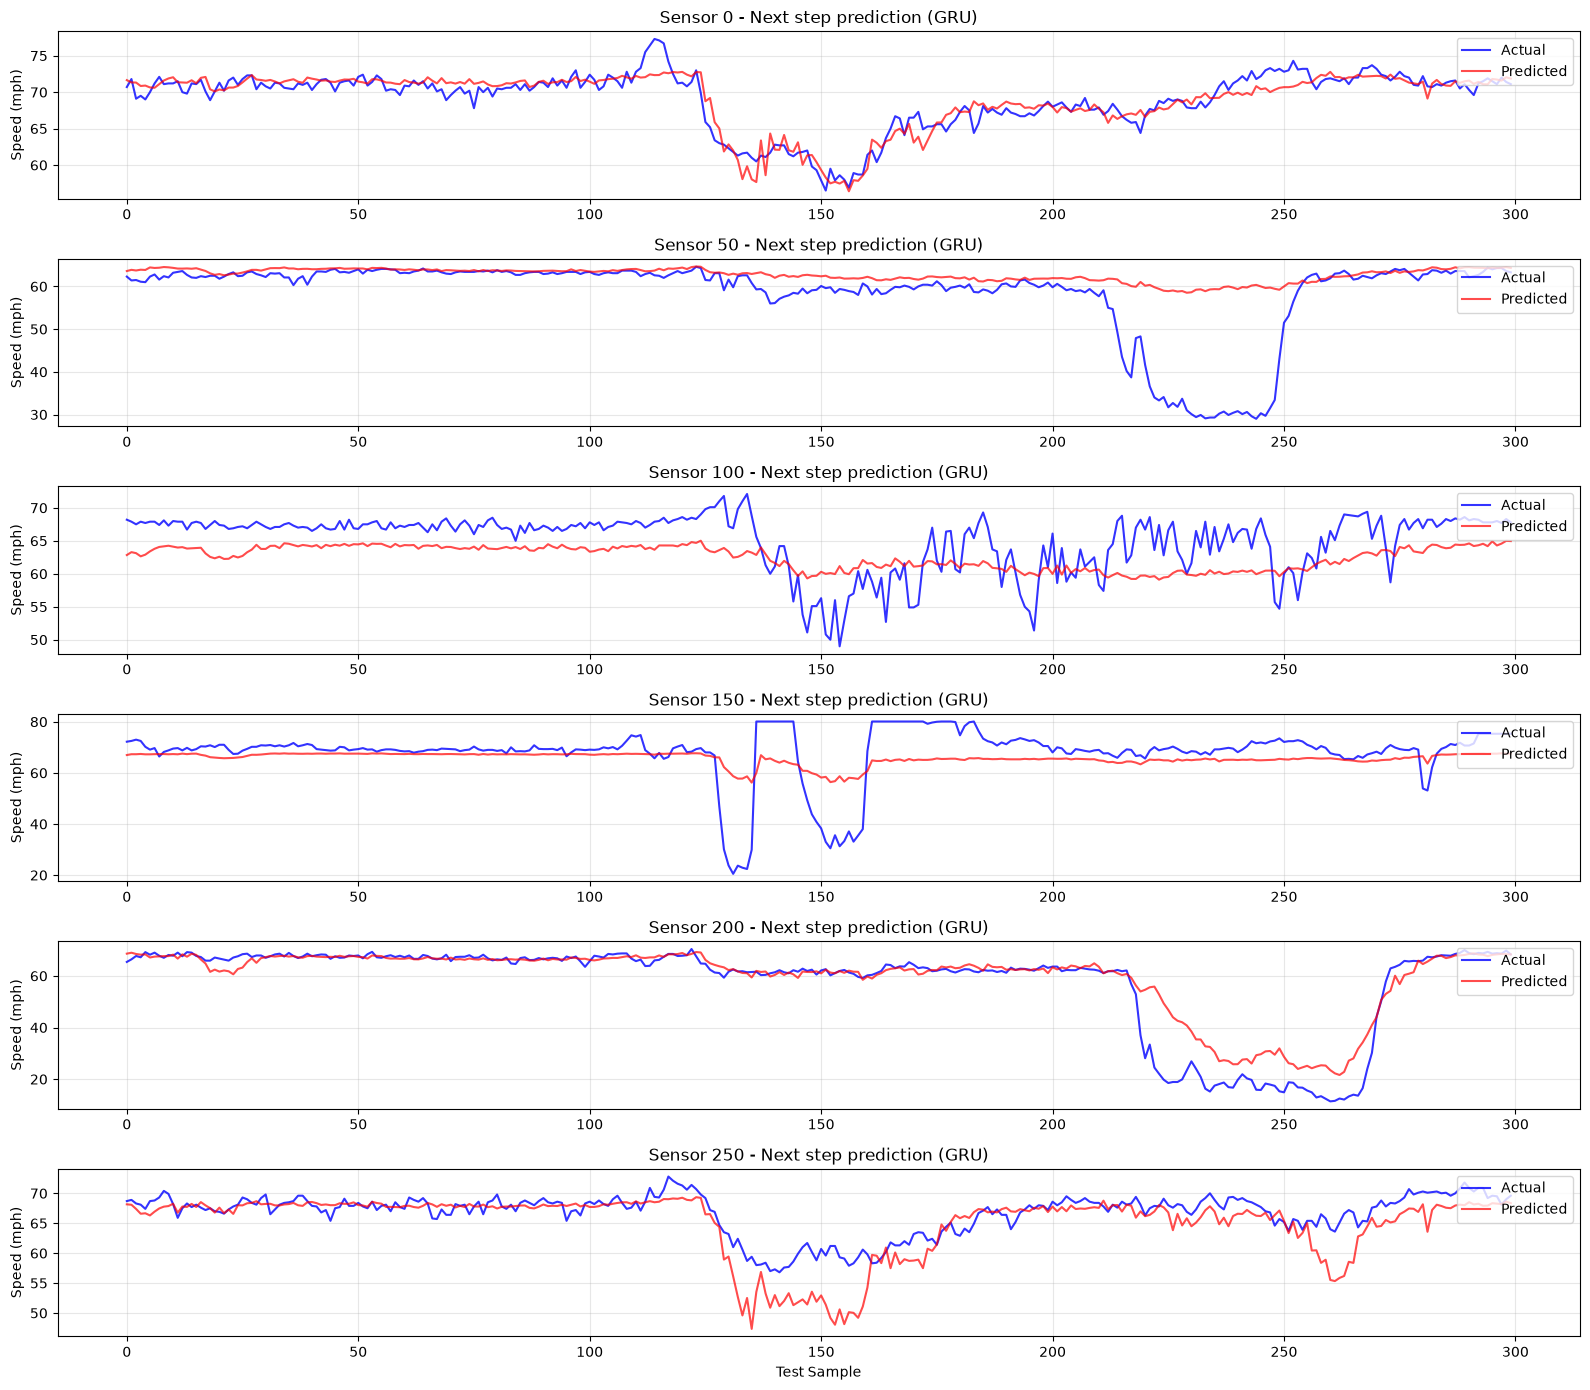

In [38]:
best_model_name = results_df.index[0]
best_model = models[best_model_name]

y_pred = best_model.predict(X_test, verbose=0)
_, _, y_true_inv, y_pred_inv = calc_metrics(y_test, y_pred)

# Select some sensors to plot
sensor_ids = [0, 50, 100, 150, 200, 250]   # You can change these
n_show = 300                               # How many test samples to show

plt.figure(figsize=(16, 14))

for i, sensor in enumerate(sensor_ids):
    plt.subplot(len(sensor_ids), 1, i+1)
    
    # Plot only the first future step (t+1) for clarity
    plt.plot(y_true_inv[:n_show, 0, sensor], label='Actual', color='blue', alpha=0.8)
    plt.plot(y_pred_inv[:n_show, 0, sensor], label='Predicted', color='red', alpha=0.7)
    
    plt.title(f'Sensor {sensor} - Next step prediction ({best_model_name})')
    plt.ylabel('Speed (mph)')
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)

plt.xlabel('Test Sample')
plt.tight_layout()
plt.show()

Plot multiple future steps for one sensor

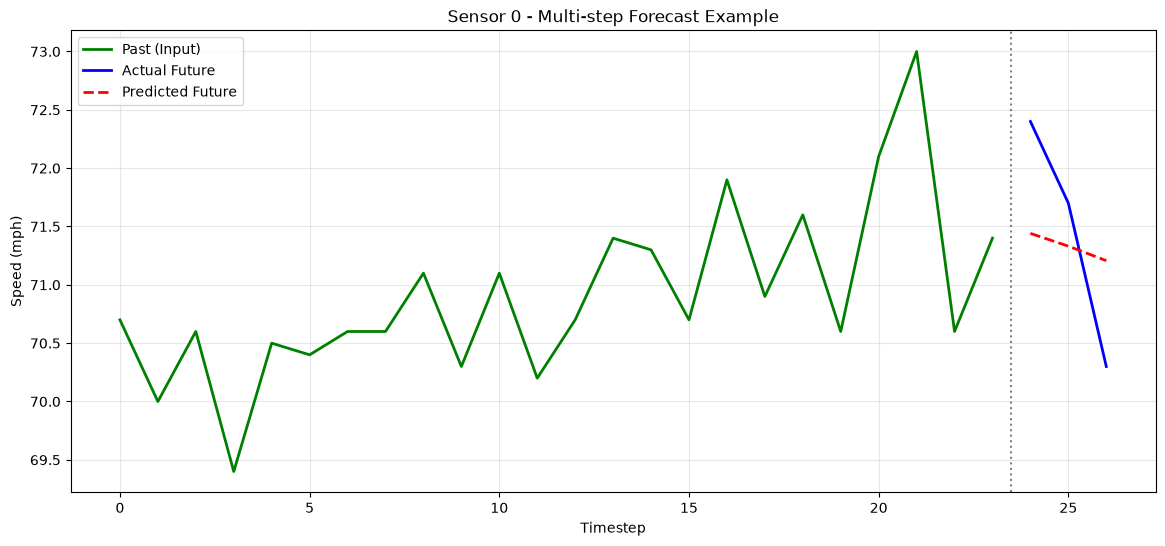

In [39]:
sensor = 0   # Change this sensor ID if you want

plt.figure(figsize=(14, 6))

# Actual
plt.plot(range(N_PAST), 
         scaler.inverse_transform(X_test[100])[:, sensor], 
         label='Past (Input)', color='green', linewidth=2)

# Future actual
plt.plot(range(N_PAST, N_PAST + N_FUTURE), 
         y_true_inv[100, :, sensor], 
         label='Actual Future', color='blue', linewidth=2)

# Future predicted
plt.plot(range(N_PAST, N_PAST + N_FUTURE), 
         y_pred_inv[100, :, sensor], 
         label='Predicted Future', color='red', linestyle='--', linewidth=2)

plt.axvline(x=N_PAST-0.5, color='gray', linestyle=':')
plt.title(f'Sensor {sensor} - Multi-step Forecast Example')
plt.xlabel('Timestep')
plt.ylabel('Speed (mph)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Save Best Model

In [40]:
best_name = results_df.index[0]
best_model = models[best_name]

best_model.save(f"pems_bay_{best_name.lower()}_forecast.h5")

with open("pems_bay_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print(f"\nSaved: pems_bay_{best_name.lower()}_forecast.h5")
print("Saved: pems_bay_scaler.pkl")


Saved: pems_bay_gru_forecast.h5
Saved: pems_bay_scaler.pkl


Now, I will create UI from these files.